<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Reto 1: Perfiles de gestión de residuos
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Mateo Benites &bull; Mateo Pastrano &bull; Saul Casanova &bull; Periodo 2026-2
            </font></p>
        </td>
    </tr>
</table>

---
## <font color='264CC7'> Introducción </font>

**Pregunta de investigación**

¿Qué perfiles de gestión de residuos aparecen en los registros municipales del Ecuador, y cómo podemos explicar en qué se diferencian para que sirvan de base a propuestas de mejora?

**Objetivo**

Se quiere agrupar a los GAD municipales por la forma en que manejan sus residuos (barrido, recolección diferenciada y recuperación de inorgánicos), no por su tamaño, y después describir cada grupo.

**Técnicas**

Se usó K-Means, que arma *k* grupos alrededor de un centroide cada uno, y un agrupamiento jerárquico con el método de Ward, que va juntando los cantones poco a poco según qué tan parecidos son. Para saber si los grupos quedan bien separados calculamos la silueta, que va de −1 a 1. Y para poder verlos en un gráfico reducimos las variables a dos componentes con PCA.

**Alcance**

Análisis exploratorio de la edición 2024. Los grupos describen patrones en los datos reportados por los municipios; no son un ranking de municipios ni prueban causas.

---
## <font color='264CC7'> Datos </font>

**Fuente:** INEC - AME, *Estadística de Información Ambiental Económica en GAD Municipales: Gestión de Residuos Sólidos*, sección "Gestión Integral de Residuos Sólidos" del portal oficial: https://www.ecuadorencifras.gob.ec/gad-municipales/

- **Edición:** 2024
- **Archivo original:** "BDD_GIRS_2024_VF.csv" (221 filas × 213 columnas)
- **Fecha de descarga:** 09/11/2026
- **Archivo usado:** "girs2024_caracteristicas.csv", con identificadores, variables descriptivas y las 5 características calculadas a partir del original

Los paquetes necesarios son:

In [1]:
# Paquetes necesarios
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples
from scipy.cluster.hierarchy import linkage, dendrogram

In [2]:
# Cargar datos desde GitHub
URL = "https://raw.githubusercontent.com/mateo-ben/machine-learning/main/reto1/datos/girs2024_caracteristicas.csv"
df = pd.read_csv(URL, dtype={"CantonId": str})

print("Filas y columnas:", df.shape)
display(df.head())

Filas y columnas: (221, 12)


,CantonId,NombreCanton,rgnatu,Pob,MSF,log_crr,cob_barrido,prop_diferenciada,prop_recuperada,ppc,trata_organicos,motivo_exclusion
0,101,CUENCA,1,374870,1,4.150087,0.863699,0.0,0.009443,1.08,1,NaN
1,102,GIRON,1,4491,1,2.110590,0.284363,1.0,0.018045,0.58,1,NaN
2,103,GUALACEO,1,14336,0,2.681241,1.000000,0.0,0.000000,0.46,0,NaN
3,104,NABON,1,1301,1,1.875061,0.998906,0.0,0.000000,0.58,0,NaN
4,105,PAUTE,1,9056,0,2.556303,1.000000,0.0,0.000128,0.59,0,NaN


---
## <font color='264CC7'> Auditoría y características </font>

**Auditoría de la base original:**
- Hay 221 cantones, uno por fila, sin duplicados ni filas de totales.
- "BOLÍVAR" y "OLMEDO" se repiten en dos provincias, así que identificamos los cantones por "CantonId".

**Características elegidas:**

| Característica | Construcción (códigos INEC) | Unidad | Motivo |
|---|---|---|---|
| "log_crr" | log10(CRR) | log de t/mes | Única medida de escala. CRR va de 15 a 121 906 t/mes, y el logaritmo evita que Guayaquil y Quito dominen |
| "cob_barrido" | VB / (MR4221 + MR4222), tope 1 | proporción | Barrido de calles |
| "prop_diferenciada" | DIF / MR453, tope 1 | proporción | Separación en la recolección |
| "prop_recuperada" | (RI / 1000) / CRR | proporción | Recuperación de inorgánicos |
| "ppc" | MR4321 | kg/hab/día | Generación por habitante |

**Decisiones**

Para la cobertura de barrido se recalculó el denominador como urbano + rural, ya que el total MR4223 está mal sumado en 7 cantones. En la variable original CSB había cinco vacíos y cuatro valores mayores a uno. Latacunga e Isabela pasaban de uno por ese total mal sumado, y al recalcular el denominador quedan en 0.98 y 1.00. Biblián y Suscal siguen por encima porque el barrido manual y el mecánico se superponen; solo en esos dos casos se puso un tope de 1, ya que una cobertura mayor al 100 % no tiene sentido.

Se descartaron estas variables:

- "VB" y "CRR" sin transformar, porque reflejan sobre todo el tamaño del cantón (su correlación de Spearman con la población es de 0.66 y 0.94).
- "TROT" (cantidad total de residuos orgánicos tratados, t/mes). Se obtiene sumando MR4441 y MR4442, pero el diccionario describe esos campos como kg/año y como kg/mes al mismo tiempo. En 16 cantones TROT supera todo lo que el cantón recolecta (en Antonio Ante aparecen 3 722 t/mes tratadas frente a 682 recolectadas), lo que hace pensar que algunos municipios reportaron cifras anuales. Por eso solo se usó como variable de sí/no ("trata_organicos").
- "PORG", porque solo hay datos para 108 cantones.
- "RIR", porque es el mismo dato que "RI" pero en toneladas; incluir las dos sería contar dos veces la recuperación de inorgánicos.

Las columnas "rgnatu", "Pob", "MSF" y "trata_organicos" quedaron fuera del agrupamiento y se usan únicamente para describir los perfiles. "Pob" tampoco se usa como denominador.

In [3]:
CARACT = ["log_crr", "cob_barrido", "prop_diferenciada", "prop_recuperada", "ppc"]

print("Cantones únicos:", df["CantonId"].nunique())
display(df[CARACT].isna().sum())
display(df.loc[df["cob_barrido"].isna(), ["NombreCanton", "motivo_exclusion"]])

Cantones únicos: 221


,0
log_crr,0
cob_barrido,6
prop_diferenciada,0
prop_recuperada,0
ppc,0


,NombreCanton,motivo_exclusion
141,MONTECRISTI,faltante: sin longitud de calles definida
144,ROCAFUERTE,faltante: sin longitud de calles definida
156,GUALAQUIZA,no aplica: sin servicio de barrido
188,PATATE,faltante: sin longitud de calles definida
189,QUERO,faltante: sin longitud de calles definida
201,PAQUISHA,no aplica: sin servicio de barrido


"cob_barrido" falta en 6 cantones:
- Montecristi, Rocafuerte, Patate y Quero no definieron la longitud de calles a barrer (dato faltante).
- Gualaquiza y Paquisha no tienen servicio de barrido (no aplica).

Este valor no se rellenó ya que poner un 0 daría a entender que el cantón no barre, cuando Montecristi barre 70 km, y poner un 1 significaría cobertura total donde no hay servicio.  En cambio, los ceros de "prop_diferenciada" y "prop_recuperada" son ceros reales: el municipio reportó que no realiza esa actividad.

---
## <font color='264CC7'> Preparación de la matriz </font>

Trabajamos con los 215 cantones completos. No eliminamos atípicos como Guayaquil o Quito, porque el logaritmo ya reduce su peso. Estandarizamos las 5 características para que todas pesen igual en la distancia euclidiana.

In [4]:
m = df.dropna(subset=CARACT).reset_index(drop=True)
print("Cantones para agrupar:", len(m))
display(m[CARACT].describe().round(3))

Cantones para agrupar: 215


,log_crr,cob_barrido,prop_diferenciada,prop_recuperada,ppc
count,215.000,215.000,215.000,215.000,215.000
mean,2.625,0.845,0.289,0.011,0.628
std,0.660,0.237,0.444,0.037,0.181
min,1.185,0.090,0.000,0.000,0.230
25%,2.156,0.733,0.000,0.000,0.510
50%,2.581,1.000,0.000,0.000,0.620
75%,3.021,1.000,1.000,0.003,0.750
max,5.086,1.000,1.000,0.366,1.410


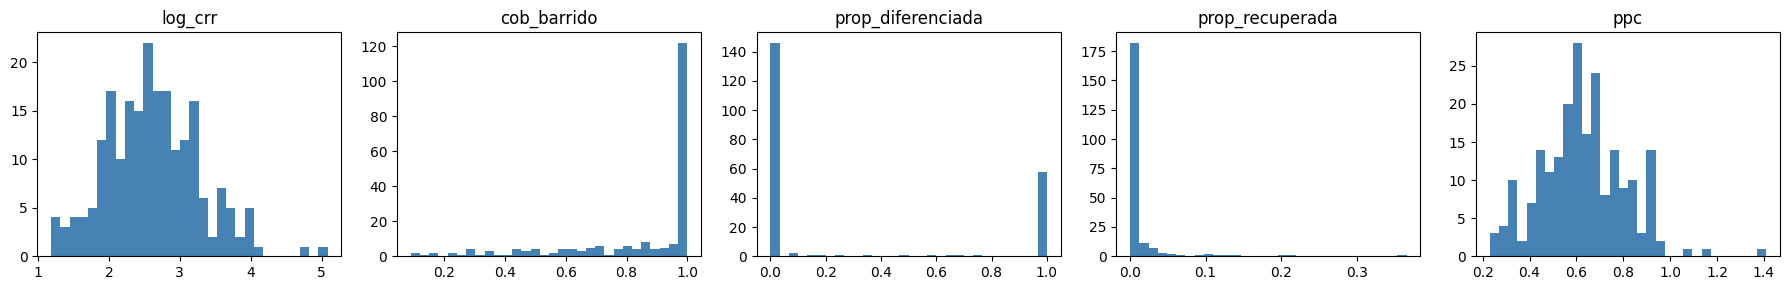

,log_crr,cob_barrido,prop_diferenciada,prop_recuperada,ppc
log_crr,1.00,-0.10,-0.18,-0.08,0.48
cob_barrido,-0.10,1.00,-0.15,-0.12,-0.10
prop_diferenciada,-0.18,-0.15,1.00,0.33,-0.13
prop_recuperada,-0.08,-0.12,0.33,1.00,-0.07
ppc,0.48,-0.10,-0.13,-0.07,1.00


In [5]:
# Distribución de las características
fig, ejes = plt.subplots(1, 5, figsize=(18, 3))
for i, var in enumerate(CARACT):
    ejes[i].hist(m[var], bins=30, color="steelblue")
    ejes[i].set_title(var)
plt.tight_layout()
plt.show()

m[CARACT].corr(method="spearman").round(2)

- "log_crr" y "ppc" tienen distribuciones más o menos simétricas.
- "cob_barrido" se acumula en 1: más de la mitad de los cantones reporta cobertura total.
- "prop_diferenciada" y "prop_recuperada" tienen muchos ceros (150 y 134 cantones), así que esperamos que los grupos separen a los cantones que sí y no realizan esas prácticas.
- Las correlaciones son bajas (la mayor es 0.48, entre "log_crr" y "ppc"), así que las características no repiten información.

In [6]:
X = StandardScaler().fit_transform(m[CARACT])
X.shape

(215, 5)

---
## <font color='264CC7'> Agrupamiento </font>

Se aplicaron K-Means y el agrupamiento jerárquico sobre la misma matriz, probando valores de k entre 2 y 6.

En el jerárquico se usó el enlace de **Ward** con distancia **euclidiana**. En cada paso, Ward junta los dos grupos cuya unión aumenta menos la varianza interna, que es exactamente lo que minimiza K-Means, y por eso los resultados de ambos métodos se pueden comparar.

En K-Means se fijó la semilla principal con "random_state=0" y se usó "n_init=50", o sea que el algoritmo arranca 50 veces desde puntos distintos y se queda con la mejor solución. De esa forma el resultado no depende de una única inicialización.

In [7]:
resultados = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=50, random_state=0).fit_predict(X)
    wa = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    resultados.append({
        "k": k,
        "silueta K-Means": silhouette_score(X, km),
        "silueta Ward": silhouette_score(X, wa),
        "tamaños K-Means": sorted(np.bincount(km).tolist(), reverse=True),
        "tamaños Ward": sorted(np.bincount(wa).tolist(), reverse=True),
    })

tabla = pd.DataFrame(resultados).round(3)
tabla

,k,silueta K-Means,silueta Ward,tamaños K-Means,tamaños Ward
0,2,0.314,0.211,"[150, 65]","[127, 88]"
1,3,0.253,0.213,"[86, 66, 63]","[127, 53, 35]"
2,4,0.281,0.226,"[86, 66, 58, 5]","[127, 49, 35, 4]"
3,5,0.308,0.265,"[76, 52, 49, 33, 5]","[80, 49, 47, 35, 4]"
4,6,0.326,0.286,"[74, 49, 38, 30, 19, 5]","[80, 47, 35, 30, 19, 4]"


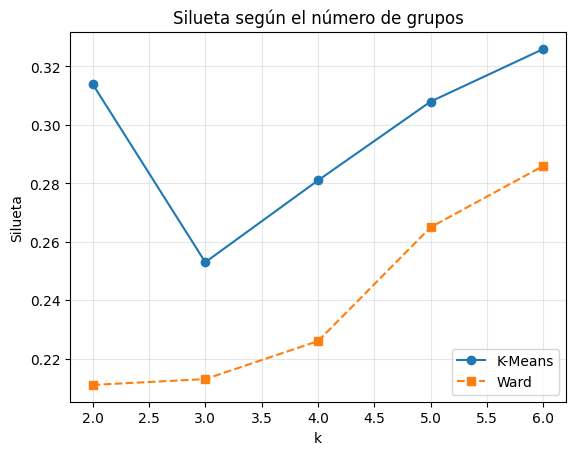

In [8]:
plt.plot(tabla["k"], tabla["silueta K-Means"], "o-", label="K-Means")
plt.plot(tabla["k"], tabla["silueta Ward"], "s--", label="Ward")
plt.xlabel("k")
plt.ylabel("Silueta")
plt.title("Silueta según el número de grupos")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

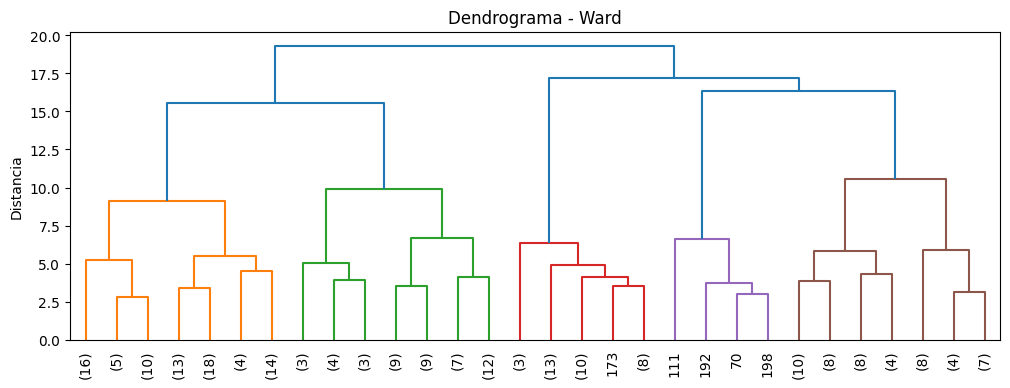

In [9]:
# Dendrograma (Ward)
Z = linkage(X, method="ward")
plt.figure(figsize=(12, 4))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90)
plt.title("Dendrograma - Ward")
plt.ylabel("Distancia")
plt.show()

**Comparación:**
- K-Means tiene mejor silueta que Ward en todos los valores de k.
- Desde k = 4, los dos métodos forman un grupo muy pequeño (4 o 5 cantones) junto a grupos grandes.
- La silueta más alta es la de k = 6 (0.33), seguida de k = 2 (0.31) y k = 5 (0.31).
- Todas las siluetas están entre 0.21 y 0.33. Es un agrupamiento **débil**: los perfiles son tendencias, no grupos totalmente separados.

### Distintas inicializaciones de K-Means
Para k = 5, comparamos 5 semillas con una sola inicialización ("n_init=1") y con 50 inicializaciones ("n_init=50").

In [10]:
filas = []
for inicializaciones in [1, 50]:
    for semilla in [0, 1, 2, 3, 4]:
        etiquetas = KMeans(n_clusters=5, n_init=inicializaciones, random_state=semilla).fit_predict(X)
        filas.append({
            "n_init": inicializaciones,
            "semilla": semilla,
            "silueta": round(silhouette_score(X, etiquetas), 3),
            "tamaños": sorted(np.bincount(etiquetas).tolist(), reverse=True),
        })

pd.DataFrame(filas)

,n_init,semilla,silueta,tamaños
0,1,0,0.301,"[78, 53, 51, 30, 3]"
1,1,1,0.300,"[80, 52, 42, 38, 3]"
2,1,2,0.305,"[82, 57, 41, 30, 5]"
3,1,3,0.300,"[81, 56, 42, 33, 3]"
4,1,4,0.304,"[81, 51, 42, 36, 5]"
5,50,0,0.308,"[76, 52, 49, 33, 5]"
6,50,1,0.308,"[76, 52, 49, 33, 5]"
7,50,2,0.308,"[76, 52, 49, 33, 5]"
8,50,3,0.308,"[76, 52, 49, 33, 5]"
9,50,4,0.308,"[76, 52, 49, 33, 5]"


In [11]:
# k = 6 con distintas semillas
for semilla in [0, 1, 2, 3, 4]:
    etiquetas = KMeans(n_clusters=6, n_init=50, random_state=semilla).fit_predict(X)
    print(semilla, round(silhouette_score(X, etiquetas), 3), sorted(np.bincount(etiquetas).tolist(), reverse=True))

0 0.326 [74, 49, 38, 30, 19, 5]
1 0.326 [76, 49, 38, 27, 20, 5]
2 0.326 [77, 48, 38, 27, 20, 5]
3 0.327 [76, 49, 38, 28, 19, 5]
4 0.327 [76, 49, 38, 28, 19, 5]


Con una sola inicialización, la silueta y el tamaño de los grupos cambian según la semilla, y con algunas semillas cambian incluso los grupos que se forman. Esto pasa porque K-Means puede quedarse en soluciones distintas que son casi igual de buenas.

Con 50 inicializaciones, las 5 semillas probadas llegan a la misma solución (grupos de 76, 52, 49, 33 y 5 cantones), y por eso se usó "n_init=50". Con k = 6 la silueta casi no cambia entre semillas (va de 0.326 a 0.327), aunque los tamaños sí se mueven un poco.

**Elección de k**

Se eligió K-Means con k = 5.

Con k = 2 solo se separan los cantones que hacen recolección diferenciada de los que no, y eso aporta poco. k = 6 tiene la silueta más alta, pero la diferencia con k = 5 es pequeña (0.33 frente a 0.31). Lo único que agrega es partir el grupo de recolección diferenciada en dos según la cobertura de barrido, y encima sus tamaños dependen de la semilla. k = 5, en cambio, da siempre la misma solución y cada grupo se puede interpretar sin problema.

**Cantidades absolutas vs. logaritmo**

Para ver el efecto de la escala, repetimos K-Means (k = 5) usando los residuos recolectados en t/mes, sin logaritmo, en lugar de "log_crr".

In [12]:
m["CRR_t_mes"] = 10 ** m["log_crr"]
absolutas = ["CRR_t_mes", "cob_barrido", "prop_diferenciada", "prop_recuperada", "ppc"]

X_abs = StandardScaler().fit_transform(m[absolutas])
g_abs = KMeans(n_clusters=5, n_init=50, random_state=0).fit_predict(X_abs)

print("Silueta:", round(silhouette_score(X_abs, g_abs), 3))
print("Tamaños:", sorted(np.bincount(g_abs).tolist(), reverse=True))
m.loc[pd.Series(g_abs).map(pd.Series(g_abs).value_counts()) <= 2, "NombreCanton"]

Silueta: 0.349
Tamaños: [84, 65, 56, 8, 2]


,NombreCanton
73,GUAYAQUIL
173,QUITO


Con la cantidad recolectada en t/mes, sin logaritmo, la silueta sube a 0.349, pero Guayaquil y Quito forman un grupo aparte solo por su tamaño. Por eso usamos el logaritmo, aunque la silueta baje a 0.308: una métrica más alta no garantiza grupos más útiles.

In [13]:
K = 5
m["grupo"] = KMeans(n_clusters=K, n_init=50, random_state=0).fit_predict(X)
m["grupo_ward"] = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X)
m["silueta"] = silhouette_samples(X, m["grupo"])

---
## <font color='264CC7'> PCA </font>

Usamos el PCA solo para visualizar. La silueta se calculó con las 5 características estandarizadas, no con las 2 componentes.

Varianza explicada: [0.327 0.249 0.175 0.156 0.093]
Varianza acumulada: [0.327 0.576 0.751 0.907 1.   ]


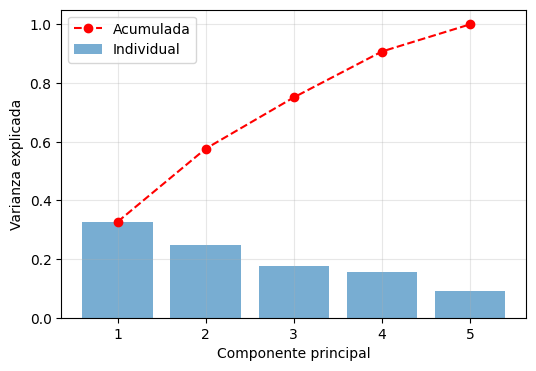

In [14]:
pca = PCA()
pca.fit(X)
varianza = pca.explained_variance_ratio_
print("Varianza explicada:", varianza.round(3))
print("Varianza acumulada:", varianza.cumsum().round(3))

plt.figure(figsize=(6, 4))
plt.bar(range(1, 6), varianza, alpha=0.6, label="Individual")
plt.plot(range(1, 6), varianza.cumsum(), marker="o", linestyle="--", color="red", label="Acumulada")
plt.xlabel("Componente principal")
plt.ylabel("Varianza explicada")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [15]:
loadings = pd.DataFrame(pca.components_[:2].T, columns=["PC1", "PC2"], index=CARACT)
loadings.round(2)

,PC1,PC2
log_crr,0.66,-0.17
cob_barrido,0.05,0.68
prop_diferenciada,-0.37,-0.38
prop_recuperada,-0.19,-0.55
ppc,0.63,-0.26


- **PC1 (32.7%):** aumenta con "log_crr" (0.66) y "ppc" (0.63). Representa el tamaño y la generación de residuos.
- **PC2 (24.9%):** aumenta con "cob_barrido" (0.68) y disminuye con "prop_recuperada" (−0.55) y "prop_diferenciada" (−0.38). Opone el barrido completo a la separación y recuperación.

Las dos juntas explican el 57.6 % de la varianza.

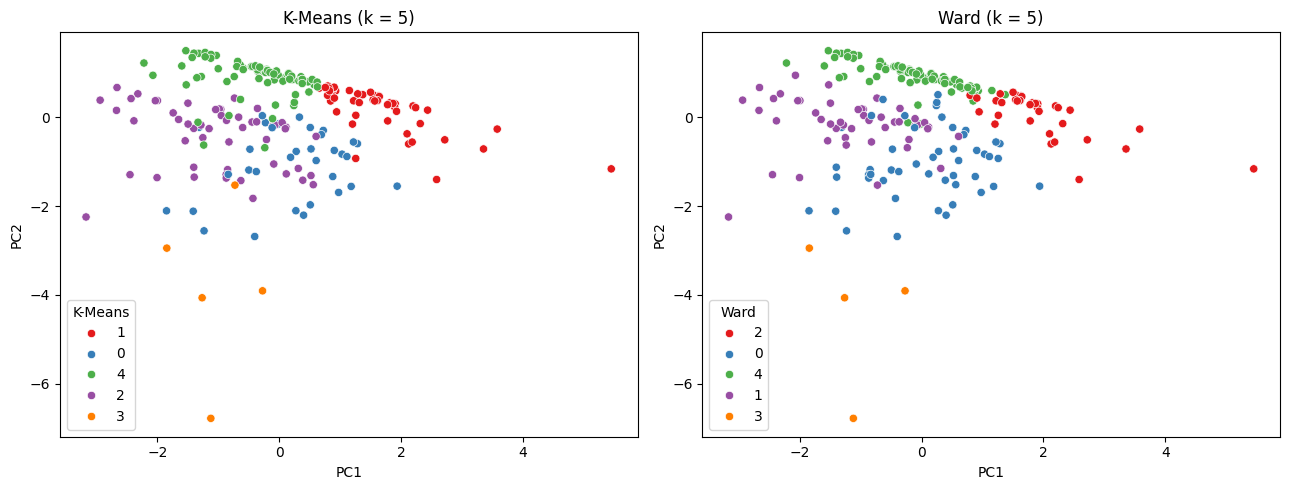

In [16]:
df_pca = pd.DataFrame(pca.transform(X)[:, :2], columns=["PC1", "PC2"])
df_pca["K-Means"] = m["grupo"].astype(str)
df_pca["Ward"] = m["grupo_ward"].astype(str)

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=df_pca, x="PC1", y="PC2", hue="K-Means", palette="Set1", ax=ejes[0])
sns.scatterplot(data=df_pca, x="PC1", y="PC2", hue="Ward", palette="Set1", ax=ejes[1])
ejes[0].set_title("K-Means (k = 5)")
ejes[1].set_title("Ward (k = 5)")
plt.tight_layout()
plt.show()

### Ubicación de los perfiles en el PCA

La correspondencia entre el número de grupo de la leyenda y el nombre del perfil se muestra en la sección Perfiles.

- **Urbanos de mayor escala:** a la derecha (PC1 alto: más tamaño y más generación por habitante).
- **Recolección diferenciada:** a la izquierda.
- **Pequeños con servicio básico:** arriba (cobertura completa, sin separación).
- **Barrido limitado:** abajo, cerca del centro.
- **Recuperación activa:** muy abajo, separada del resto.

Los dos métodos coinciden en los grupos de los extremos y se diferencian en el centro, donde los grupos se solapan. Esto coincide con la silueta baja.

---
## <font color='264CC7'> Perfiles </font>

Nombramos cada grupo según sus valores promedio. El número del grupo no indica un orden de calidad.

In [17]:
promedios = m.groupby("grupo")[CARACT].mean()

def nombrar(g):
    if g["prop_recuperada"] > 0.10:
        return "Recuperación activa de inorgánicos"
    if g["prop_diferenciada"] > 0.50:
        return "Recolección diferenciada"
    if g["cob_barrido"] < 0.60:
        return "Barrido limitado"
    if g["log_crr"] > 3:
        return "Urbanos de mayor escala, sin separación"
    return "Pequeños con servicio básico completo"

m["perfil"] = m["grupo"].map(promedios.apply(nombrar, axis=1))
m["CRR_t_mes"] = 10 ** m["log_crr"]

perfiles = m.groupby("perfil").agg(
    cantones=("CantonId", "count"),
    residuos_t_mes=("CRR_t_mes", "median"),
    poblacion_urbana=("Pob", "median"),
    cob_barrido=("cob_barrido", "median"),
    prop_diferenciada=("prop_diferenciada", "mean"),
    prop_recuperada=("prop_recuperada", "mean"),
    ppc=("ppc", "median"),
    separa_fuente=("MSF", "mean"),
    trata_organicos=("trata_organicos", "mean"),
)
perfiles.round(3)

,cantones,residuos_t_mes,poblacion_urbana,cob_barrido,prop_diferenciada,prop_recuperada,ppc,separa_fuente,trata_organicos
perfil,,,,,,,,,
Barrido limitado,33,420.000,8340.0,0.431,0.175,0.004,0.700,0.273,0.242
Pequeños con servicio básico completo,76,249.150,5647.0,1.000,0.008,0.006,0.525,0.118,0.118
Recolección diferenciada,52,207.300,5457.5,1.000,0.982,0.012,0.580,0.673,0.692
Recuperación activa de inorgánicos,5,437.100,12746.0,0.444,0.495,0.209,0.700,0.400,0.400
"Urbanos de mayor escala, sin separación",49,1800.002,47742.0,1.000,0.046,0.002,0.810,0.082,0.163


In [18]:
# Número de grupo (leyenda del PCA) y nombre del perfil
m.groupby("grupo")["perfil"].first()

,perfil
grupo,
0,Barrido limitado
1,"Urbanos de mayor escala, sin separación"
2,Recolección diferenciada
3,Recuperación activa de inorgánicos
4,Pequeños con servicio básico completo


La misma proyección del PCA, pero con el nombre de cada perfil. Esta es la Figura 3 del informe; la celda la guarda como "figura3_pca.png".

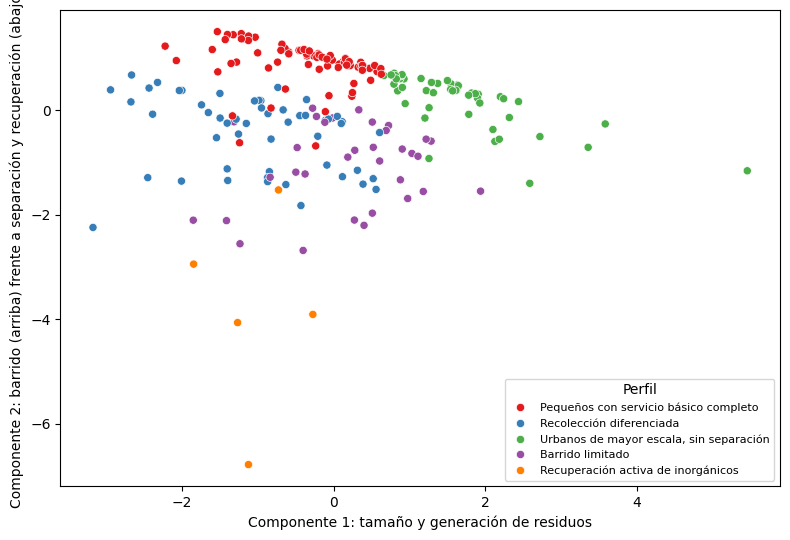

In [19]:
# Figura 3 del informe: PCA coloreado por perfil
df_pca["perfil"] = m["perfil"]
orden = ["Pequeños con servicio básico completo", "Recolección diferenciada",
         "Urbanos de mayor escala, sin separación", "Barrido limitado",
         "Recuperación activa de inorgánicos"]

plt.figure(figsize=(8, 5.5))
sns.scatterplot(data=df_pca, x="PC1", y="PC2", hue="perfil", hue_order=orden, palette="Set1", s=35)
plt.xlabel("Componente 1: tamaño y generación de residuos")
plt.ylabel("Componente 2: barrido (arriba) frente a separación y recuperación (abajo)")
plt.legend(title="Perfil", fontsize=8)
plt.tight_layout()
plt.savefig("figura3_pca.png", dpi=300)
plt.show()

In [20]:
region = m["rgnatu"].map({1: "Sierra", 2: "Costa", 3: "Amazonía", 4: "Galápagos"})
pd.crosstab(m["perfil"], region)

rgnatu,Amazonía,Costa,Galápagos,Sierra
perfil,,,,
Barrido limitado,5,12,0,16
Pequeños con servicio básico completo,13,27,0,36
Recolección diferenciada,18,7,1,26
Recuperación activa de inorgánicos,1,1,2,1
"Urbanos de mayor escala, sin separación",2,35,0,12


Las cantidades de residuos y la población se resumen con la mediana, porque son muy asimétricas. Las proporciones se resumen con el promedio: "prop_recuperada = 0.209" se lee como "en promedio, el 20.9 % de lo recolectado".

| Perfil | Cantones | Descripción |
|---|---|---|
| **Pequeños con servicio básico completo** | 76 | Cantones pequeños (mediana: 249 t/mes y unos 5 600 habitantes urbanos). Barren casi todo, pero casi no separan ni recuperan, y solo el 12% separa en la fuente |
| **Recolección diferenciada** | 52 | Cantones pequeños. Mayormente recolección diferenciada (98%), el 67 % separa en la fuente y el 69 % trata orgánicos, pero recuperan poco inorgánico (1.2%). Están más en la Sierra y la Amazonía |
| **Urbanos de mayor escala, sin separación** | 49 | Los más grandes (mediana: 1 800 t/mes y unos 47 700 habitantes urbanos), con la mayor generación por habitante (0.81 kg/hab/día). Casi no separan. 35 de los 49 están en la Costa |
| **Barrido limitado** | 33 | La mediana de cobertura de barrido es 43%. Separan y recuperan poco |
| **Recuperación activa de inorgánicos** | 5 | Recuperan en promedio el 21% de lo recolectado: Macará, San Lorenzo, Yantzaza, Isabela y Santa Cruz (2 de Galápagos) |

**Ejemplos y cantones poco representados.** La silueta de cada cantón indica si encaja en su perfil: si es negativa, el cantón se parece más a otro grupo.

In [21]:
# Algunos cantones de cada perfil
display(m.groupby("perfil").head(3)[["perfil", "NombreCanton"] + CARACT].sort_values("perfil").round(2))

# Cantones que no encajan bien en su perfil
m[m["silueta"] < 0][["NombreCanton", "perfil", "silueta"] + CARACT].round(2)

,perfil,NombreCanton,log_crr,cob_barrido,prop_diferenciada,prop_recuperada,ppc
1,Barrido limitado,GIRON,2.11,0.28,1.00,0.02,0.58
5,Barrido limitado,PUCARA,1.83,0.67,0.00,0.00,0.78
11,Barrido limitado,EL PAN,1.18,0.67,0.00,0.00,0.90
2,Pequeños con servicio básico completo,GUALACEO,2.68,1.00,0.00,0.00,0.46
3,Pequeños con servicio básico completo,NABON,1.88,1.00,0.00,0.00,0.58
4,Pequeños con servicio básico completo,PAUTE,2.56,1.00,0.00,0.00,0.59
6,Recolección diferenciada,SAN FERNANDO,2.00,0.45,1.00,0.00,0.58
7,Recolección diferenciada,SANTA ISABEL,2.51,1.00,0.67,0.00,0.52
9,Recolección diferenciada,ONA,1.22,1.00,1.00,0.00,0.51
70,Recuperación activa de inorgánicos,SAN LORENZO,2.88,0.44,0.00,0.20,0.71


,NombreCanton,perfil,silueta,log_crr,cob_barrido,prop_diferenciada,prop_recuperada,ppc
14,CAMILO PONCE ENRIQUEZ,Barrido limitado,-0.11,2.86,0.70,0.00,0.00,0.58
65,LAS LAJAS,Barrido limitado,-0.08,2.08,0.67,0.00,0.00,0.63
197,ISABELA,Recuperación activa de inorgánicos,-0.06,2.38,1.00,0.48,0.13,0.70


Tres cantones tienen silueta negativa:
- **Camilo Ponce Enríquez** y **Las Lajas** quedaron en Barrido limitado con una cobertura de 0.67 a 0.70. Están en la frontera con los perfiles de cobertura completa.
- **Isabela** quedó en Recuperación activa. Recupera el 13 %, pero tiene cobertura total de barrido y por eso también se parece a otros grupos.

Estos casos muestran que los perfiles no tienen fronteras nítidas.

### Estabilidad de los perfiles

- **Semillas:** con `n_init=50`, las 5 semillas probadas dan exactamente los mismos grupos (76, 52, 49, 33 y 5 cantones).
- **Métodos:** en el gráfico del PCA, K-Means y Ward coinciden en los perfiles de los extremos (Recuperación activa y Barrido limitado) y se diferencian en la zona central, donde los grupos se solapan. Ward también forma 5 grupos de tamaños parecidos (80, 49, 47, 35 y 4).
- **Número de grupos:** al aumentar k, los perfiles se van sumando sin desaparecer. Con k = 2 se separa la recolección diferenciada, y esa división se mantiene en todas las soluciones. Con k = 3 aparecen los urbanos de mayor escala, con k = 4 el grupo de 5 cantones de recuperación activa y con k = 5 el de barrido limitado. Con k = 6 solo se divide el grupo de recolección diferenciada según su cobertura de barrido.
- **Cantones de frontera:** los 3 cantones con silueta negativa y la silueta media de 0.31 indican que los perfiles son estables como tendencia, pero sus fronteras no son nítidas.

---
## <font color='264CC7'> Conclusiones </font>

En los registros de 2024 aparecen cinco perfiles de gestión. Además del tamaño ("log_crr"), los distinguen tres prácticas: hacer o no recolección diferenciada, recuperar o no inorgánicos, y el nivel de cobertura del barrido. La solución con k = 5 es estable con distintas semillas, pero la silueta (0.31) indica grupos que se sobreponen.

**Propuestas por perfil:**

| Perfil | Evidencia | Propuesta | Información que falta |
|---|---|---|---|
| Pequeños con servicio básico completo | Barren casi todo, pero solo 0.8 % de recolección diferenciada y 12 % separa en la fuente | Pilotos de recolección diferenciada en algunos barrios y alianzas con recicladores de base | Si hay recicladores o gestores en el cantón y el costo de un piloto |
| Urbanos de mayor escala, sin separación | Mediana de 1 800 t/mes, 0.81 kg/hab/día y 4.6 % de recolección diferenciada | Por su volumen, es donde la separación en la fuente y los centros de acopio tendrían más impacto en toneladas | Composición de sus residuos (pocos la reportan) y capacidad de su sitio de disposición final |
| Recolección diferenciada | 98 % de recolección diferenciada, pero solo 1.2 % de inorgánicos recuperados | Revisar qué pasa después de recolectar: si hay mercado o gestores para el material separado | Destino del material separado y precios de venta |
| Barrido limitado | Mediana de cobertura de barrido de 43 % | Verificar si la baja cobertura se debe a falta de recursos o a problemas de registro | Personal y equipos de barrido, y cómo se midió la longitud de calles |
| Recuperación activa de inorgánicos | Recuperan en promedio el 21 % de lo recolectado | Documentar su experiencia como referencia para otros municipios | Cómo se organizan (asociaciones, convenios) y si el dato se mantiene en otros años |

**Limitaciones:**
- Los datos son autorreportados por cada municipio. Encontramos totales mal sumados y valores de "TROT" que no son coherentes con su unidad (t/mes).
- Las proporciones tienen muchos ceros, así que los grupos reflejan sobre todo si el cantón realiza o no cada práctica.
- Se excluyeron 6 cantones sin cobertura de barrido calculable.
- Las dos primeras componentes del PCA explican solo el 57.6 % de la varianza.

**Mejoras:**
- Consultar al INEC las unidades en que reportó cada municipio los orgánicos tratados, para poder incluir "TROT" como cantidad.
- Repetir el análisis con otros años para ver si los perfiles se mantienen.